# diabetes_risk_model_Analysis

In [13]:
# Core Data Manipulation & Numerical Operations
import numpy as np
import pandas as pd
import shap
# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, f1_score
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import GridSearchCV
import xgboost as xgb
from sklearn.metrics import classification_report

import joblib

In [14]:
# Styling for visualizations
sns.set_theme(style="whitegrid")
%matplotlib inline

# Preprocessing & Feature Engineering
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Handling Class Imbalance (if needed)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb
import lightgbm as lgb

# Model Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc,
    classification_report,
    confusion_matrix
)

# Model Interpretability
import shap

### Step 1. Problem Definition & Data Collection

In [15]:
# Load the dataset
file_path = r"C:\Users\admin\Downloads\Health sector data Analysis\diabetes_risk.csv"
df = pd.read_csv(file_path)

# Display the first 5 rows
print("Dataset Head:")
display(df.head())

# Check basic info (data types, non-null counts)
print("\nDataset Info:")
df.info()

# Check for missing values per column
print("\nMissing Values Count:")
print(df.isnull().sum())

# Summary statistics for numerical features
print("\nSummary Statistics:")
display(df.describe())

Dataset Head:


,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                15000 non-null  int64  
 1   age                       15000 non-null  int64  
 2   gender                    15000 non-null  object 
 3   city                      15000 non-null  object 
 4   bmi                       15000 non-null  float64
 5   family_history_diabetes   15000 non-null  object 
 6   physical_activity_level   15000 non-null  object 
 7   diet_type                 15000 non-null  object 
 8   smoking_status            14528 non-null  object 
 9   alcohol_consumption       11212 non-null  object 
 10  hours_sleep_per_night     15000 non-null  float64
 11  stress_level              15000 non-null  int64  
 12  fasting_blood_sugar       15000 non-null  int64  
 13  hba1c_level               15000 non-null  floa

,patient_id,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,44.333667,23.062260,7.309860,5.941200,168.789933,6.878387,139.496200,86.256933,100.207933
std,4330.271354,10.383753,4.046391,1.109372,2.148406,38.365822,0.843276,12.660785,8.386529,10.760331
min,1.000000,18.000000,15.000000,3.000000,1.000000,72.000000,4.800000,80.000000,50.000000,73.200000
25%,3750.750000,38.000000,20.100000,6.700000,4.000000,145.000000,6.300000,130.000000,80.000000,92.500000
50%,7500.500000,45.000000,22.700000,7.000000,6.000000,165.000000,6.800000,140.000000,88.000000,99.300000
75%,11250.250000,52.000000,25.600000,8.000000,7.000000,189.000000,7.300000,150.000000,90.000000,106.900000
max,15000.000000,80.000000,40.800000,12.000000,10.000000,400.000000,13.400000,200.000000,120.000000,148.200000


### Sample Auditing

In [16]:
# Display all column names in your dataset
print("Columns in your dataset:")
print(df.columns.tolist())

# Automatically inspect potential target columns (columns with very few unique values, like 0 and 1)
print("\nPotential Target or Categorical Columns:")
for col in df.columns:
    if df[col].nunique() <= 5:
        print(f"Column: '{col}' | Unique Values: {df[col].unique()}")

Columns in your dataset:
['patient_id', 'age', 'gender', 'city', 'bmi', 'family_history_diabetes', 'physical_activity_level', 'diet_type', 'smoking_status', 'alcohol_consumption', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm', 'income_bracket', 'diabetes_risk']

Potential Target or Categorical Columns:
Column: 'gender' | Unique Values: ['Female' 'Male' 'Other']
Column: 'family_history_diabetes' | Unique Values: ['Yes' 'No']
Column: 'physical_activity_level' | Unique Values: ['Sedentary' 'Moderate' 'Active']
Column: 'diet_type' | Unique Values: ['Vegetarian' 'Non-Vegetarian' 'Pescatarian' 'Vegan']
Column: 'smoking_status' | Unique Values: ['Never' 'Current' nan 'Former']
Column: 'alcohol_consumption' | Unique Values: ['Never' 'Regular' 'Occasional' nan]
Column: 'income_bracket' | Unique Values: ['High' 'Low' 'Middle' nan]
Column: 'diabetes_risk' | Unique Values: ['Low' 'High'

In [17]:
print("==========================================")
print("       DIABETES RISK DATA AUDIT REPORT    ")
print("==========================================")

# 1. Dataset Dimensions
print("\n[1] DATASET DIMENSIONS")
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

# 2. Duplicate Check
duplicates = df.duplicated().sum()
print(f"\n[2] DUPLICATE ROWS: {duplicates} found")

# 3. Missing Value Audit
print("\n[3] MISSING VALUE AUDIT")
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Percentage (%)': missing_pct})
missing_active = missing_df[missing_df['Missing Count'] > 0]

if not missing_active.empty:
    display(missing_active)
else:
    print("✔ No missing values found in the dataset.")

# 4. Data Types Check
print("\n[4] DATA TYPES")
print(df.dtypes)

# 5. Numerical Range & Sanity Check
print("\n[5] NUMERICAL RANGE SANITY CHECK")
num_cols = df.select_dtypes(include=[np.number]).columns
if len(num_cols) > 0:
    # Display min, mean, max to spot anomalies (e.g., negative age, impossible BMI)
    sanity_check = df[num_cols].agg(['min', 'mean', 'max', 'std']).T
    display(sanity_check)
else:
    print("No numerical columns found.")

# 6. Categorical Distribution Audit
print("\n[6] CATEGORICAL & LOW-CARDINALITY VALUE DISTRIBUTION")
categorical_found = False
for col in df.columns:
    if df[col].nunique() <= 10:
        categorical_found = True
        print(f"\nColumn: '{col}' (Unique count: {df[col].nunique()})")
        print(df[col].value_counts(dropna=False))

if not categorical_found:
    print("No low-cardinality columns found.")

print("\n==========================================")
print("          AUDIT COMPLETE                  ")
print("==========================================")

       DIABETES RISK DATA AUDIT REPORT    

[1] DATASET DIMENSIONS
Total Rows: 15000
Total Columns: 19

[2] DUPLICATE ROWS: 0 found

[3] MISSING VALUE AUDIT


,Missing Count,Percentage (%)
smoking_status,472,3.146667
alcohol_consumption,3788,25.253333
income_bracket,463,3.086667



[4] DATA TYPES
patient_id                    int64
age                           int64
gender                       object
city                         object
bmi                         float64
family_history_diabetes      object
physical_activity_level      object
diet_type                    object
smoking_status               object
alcohol_consumption          object
hours_sleep_per_night       float64
stress_level                  int64
fasting_blood_sugar           int64
hba1c_level                 float64
blood_pressure_systolic       int64
blood_pressure_diastolic      int64
waist_circumference_cm      float64
income_bracket               object
diabetes_risk                object
dtype: object

[5] NUMERICAL RANGE SANITY CHECK


,min,mean,max,std
patient_id,1.0,7500.500000,15000.0,4330.271354
age,18.0,44.333667,80.0,10.383753
bmi,15.0,23.062260,40.8,4.046391
hours_sleep_per_night,3.0,7.309860,12.0,1.109372
stress_level,1.0,5.941200,10.0,2.148406
fasting_blood_sugar,72.0,168.789933,400.0,38.365822
hba1c_level,4.8,6.878387,13.4,0.843276
blood_pressure_systolic,80.0,139.496200,200.0,12.660785
blood_pressure_diastolic,50.0,86.256933,120.0,8.386529
waist_circumference_cm,73.2,100.207933,148.2,10.760331



[6] CATEGORICAL & LOW-CARDINALITY VALUE DISTRIBUTION

Column: 'gender' (Unique count: 3)
gender
Male      7664
Female    7183
Other      153
Name: count, dtype: int64

Column: 'family_history_diabetes' (Unique count: 2)
family_history_diabetes
No     9756
Yes    5244
Name: count, dtype: int64

Column: 'physical_activity_level' (Unique count: 3)
physical_activity_level
Active       5100
Sedentary    4950
Moderate     4950
Name: count, dtype: int64

Column: 'diet_type' (Unique count: 4)
diet_type
Non-Vegetarian    8195
Vegetarian        6074
Pescatarian        445
Vegan              286
Name: count, dtype: int64

Column: 'smoking_status' (Unique count: 3)
smoking_status
Never      10119
Current     2946
Former      1463
NaN          472
Name: count, dtype: int64

Column: 'alcohol_consumption' (Unique count: 3)
alcohol_consumption
Never         5616
Occasional    4483
NaN           3788
Regular       1113
Name: count, dtype: int64

Column: 'stress_level' (Unique count: 10)
stress_level
6

### Step 2: Data Preprocessing & Cleaning Pipeline

In [18]:
# Create a copy for preprocessing
df_clean = df.copy()

print(f"Original shape: {df_clean.shape}")

# 1. Drop unnecessary ID columns
if 'patient_id' in df_clean.columns:
    df_clean = df_clean.drop(columns=['patient_id'])

# 2. Inspect 'city' cardinality just in case
if 'city' in df_clean.columns:
    print(f"\nUnique cities count: {df_clean['city'].nunique()}")
    # If city has too many unique values, you can encode it or drop it if not predictive
    # For now, let's keep it and handle it as a categorical feature.

# 3. Handle Missing Values in Categorical Columns
# Fill missing values with a designated 'Unknown' label to retain data samples
categorical_missing_cols = ['smoking_status', 'alcohol_consumption', 'income_bracket']
for col in categorical_missing_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('Unknown')

# 4. Map or Encode Target Variable if needed
# Target: Low, Moderate, High. We can map them to integers for certain models (0, 1, 2)
risk_mapping = {'Low': 0, 'Moderate': 1, 'High': 2}
if 'diabetes_risk' in df_clean.columns:
    df_clean['diabetes_risk_encoded'] = df_clean['diabetes_risk'].map(risk_mapping)

# Verify missing values are gone
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum().sum())

print(f"\nCleaned dataset shape: {df_clean.shape}")
display(df_clean.head(3))

Original shape: (15000, 19)

Unique cities count: 18

Missing values after cleaning:
0

Cleaned dataset shape: (15000, 19)


,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk,diabetes_risk_encoded
0,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low,0
1,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low,0
2,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High,2


### Step 3: Feature Encoding, Splitting & Preprocessing Pipeline

In [19]:
# 1. Define Features (X) and Target (y)
X = df_clean.drop(columns=['diabetes_risk', 'diabetes_risk_encoded'])
y = df_clean['diabetes_risk_encoded']

# 2. Identify Numerical and Categorical columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numerical Features ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical Features ({len(categorical_cols)}): {categorical_cols}")

# 3. Split the data into Training and Test sets (80% train, 20% test)s
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

# 4. Build Preprocessing Pipelines
numeric_transformer = StandardScaler()

# Categorical features get One-Hot Encoded (handling unknown categories safely)
categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Combine into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Test the preprocessor on training data
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print(f"\nTransformed training feature matrix shape: {X_train_transformed.shape}")

Numerical Features (9): ['age', 'bmi', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm']
Categorical Features (8): ['gender', 'city', 'family_history_diabetes', 'physical_activity_level', 'diet_type', 'smoking_status', 'alcohol_consumption', 'income_bracket']

Training set shape: (12000, 17)
Test set shape: (3000, 17)

Transformed training feature matrix shape: (12000, 51)



Training set shape: (12000, 17)
Test set shape: (3000, 17)

Transformed training feature matrix shape: (12000, 51)


### Step 4: Model Training & Benchmarking

In [8]:
# Define the models to benchmark
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": xgb.XGBClassifier(random_state=42, eval_metric='mlogloss')
}

# Dictionary to store trained pipelines and results
trained_models = {}
evaluation_results = {}

print("==========================================")
print("       MODEL BENCHMARKING RESULTS         ")
print("==========================================")

for name, model in models.items():
    # Create full pipeline: Preprocessor + Model
    clf_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Train the model
    clf_pipeline.fit(X_train, y_train)
    trained_models[name] = clf_pipeline
    
    # Predict on the test set
    y_pred = clf_pipeline.predict(X_test)
    
    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    
    evaluation_results[name] = {
        "Accuracy": acc,
        "Macro F1-Score": f1_macro
    }
    
    print(f"\n--- {name} ---")
    print(f"Accuracy:      {acc:.4f}")
    print(f"Macro F1-Score: {f1_macro:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Low (0)', 'Moderate (1)', 'High (2)']))

print("==========================================")

       MODEL BENCHMARKING RESULTS         

--- Logistic Regression ---
Accuracy:      0.7850
Macro F1-Score: 0.7311

Classification Report:
              precision    recall  f1-score   support

     Low (0)       0.86      0.90      0.88      1800
Moderate (1)       0.58      0.56      0.57       750
    High (2)       0.81      0.69      0.74       450

    accuracy                           0.79      3000
   macro avg       0.75      0.72      0.73      3000
weighted avg       0.78      0.79      0.78      3000


--- Random Forest ---
Accuracy:      0.7810
Macro F1-Score: 0.7220

Classification Report:
              precision    recall  f1-score   support

     Low (0)       0.84      0.91      0.88      1800
Moderate (1)       0.58      0.53      0.56       750
    High (2)       0.81      0.67      0.73       450

    accuracy                           0.78      3000
   macro avg       0.75      0.70      0.72      3000
weighted avg       0.77      0.78      0.78      3000


--- 

### Step 5 & 6: Model Interpretability with SHAP

Generating SHAP summary plot for XGBoost...


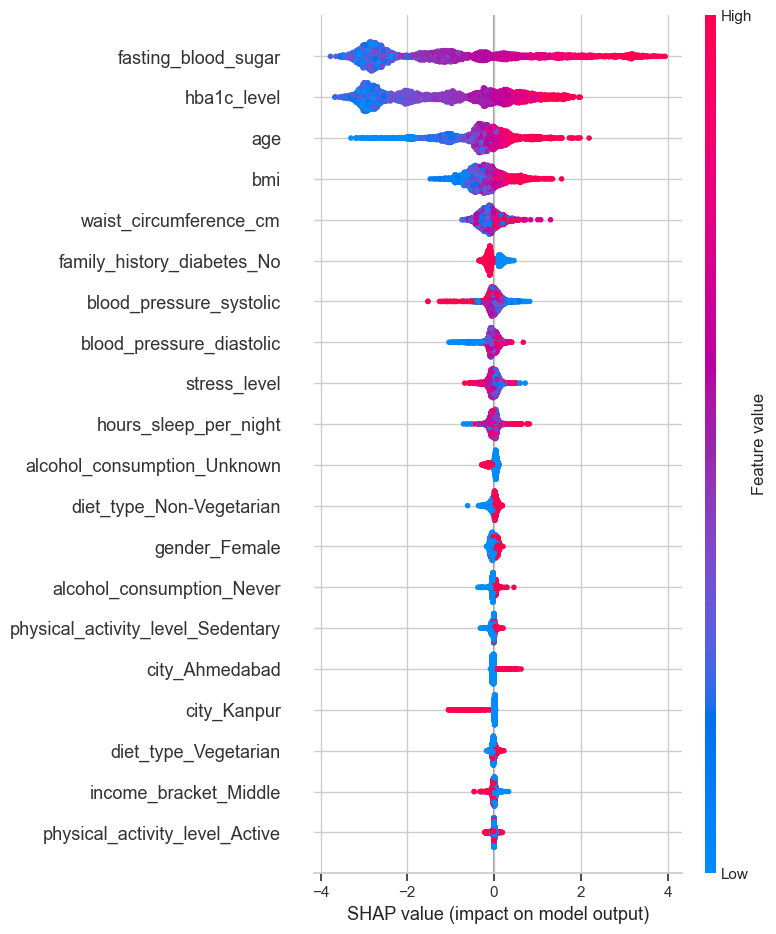

In [9]:
# 1. Select the XGBoost model pipeline instead
best_model_name = "XGBoost"
best_pipeline = trained_models[best_model_name]

# 2. Extract preprocessor and classifier
preprocessor_fitted = best_pipeline.named_steps['preprocessor']
classifier = best_pipeline.named_steps['classifier']

# 3. Transform test data and gather feature names
X_test_transformed = preprocessor_fitted.transform(X_test)
num_feature_names = numerical_cols
cat_encoder = preprocessor_fitted.named_transformers_['cat']
cat_feature_names = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_feature_names = num_feature_names + cat_feature_names

# 4. Initialize SHAP TreeExplainer for XGBoost
explainer = shap.TreeExplainer(classifier)
shap_values = explainer.shap_values(X_test_transformed)

# 5. Plot Global SHAP Summary for Multi-Class (Class 2: High Risk)
print(f"Generating SHAP summary plot for {best_model_name}...")
# For multi-class in XGBoost, shap_values might be a list or a 3D array depending on version. 
# If it's a list, index 2 corresponds to 'High (2)'.
if isinstance(shap_values, list):
    shap_values_class = shap_values[2]
else:
    # If 3D array (samples, features, classes)
    shap_values_class = shap_values[:, :, 2]

shap.summary_plot(shap_values_class, X_test_transformed, feature_names=all_feature_names)

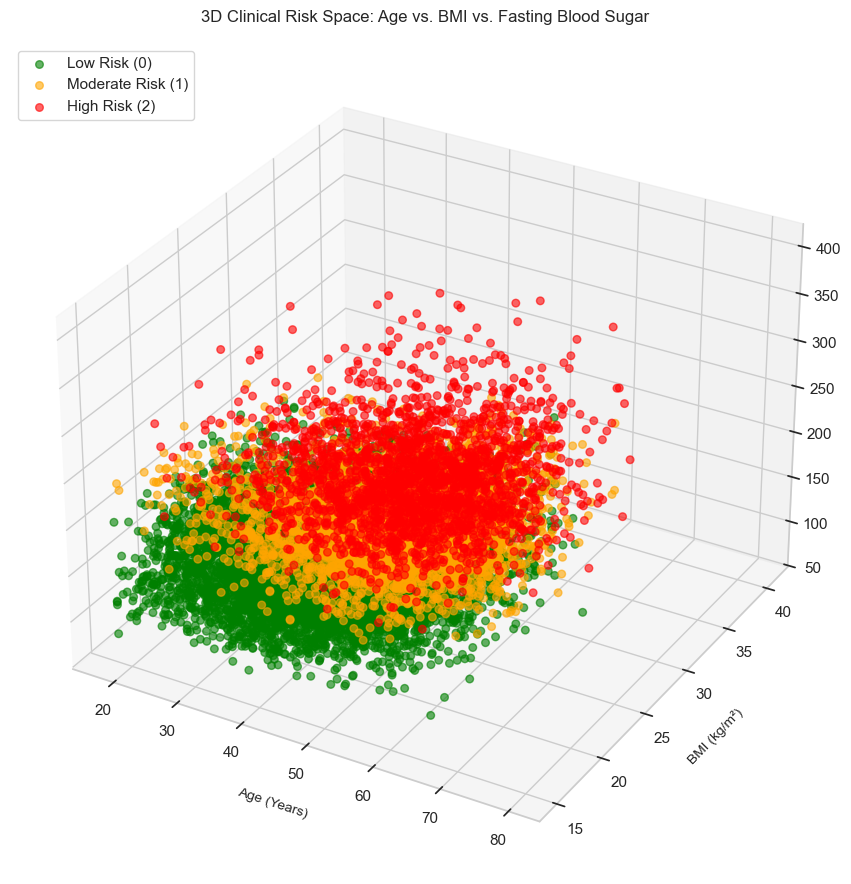

In [10]:
# Set up the 3D figure
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Select three key clinical features for the 3D axes
x_feat = 'age'
y_feat = 'bmi'
z_feat = 'fasting_blood_sugar'

# Define colors and labels for the target classes
risk_colors = {0: 'green', 1: 'orange', 2: 'red'}
risk_labels = {0: 'Low Risk (0)', 1: 'Moderate Risk (1)', 2: 'High Risk (2)'}

# Plot each risk class separately for a clear legend
for class_val, color in risk_colors.items():
    subset = df_clean[df_clean['diabetes_risk_encoded'] == class_val]
    ax.scatter(
        subset[x_feat], 
        subset[y_feat], 
        subset[z_feat], 
        c=color, 
        label=risk_labels[class_val], 
        alpha=0.6, 
        s=30
    )

# Axis labels and title
ax.set_xlabel('Age (Years)', fontsize=10, labelpad=10)
ax.set_ylabel('BMI (kg/m²)', fontsize=10, labelpad=10)
ax.set_zlabel('Fasting Blood Sugar (mg/dL)', fontsize=10, labelpad=10)
ax.set_title('3D Clinical Risk Space: Age vs. BMI vs. Fasting Blood Sugar', fontsize=12, pad=15)

# Add legend
ax.legend(loc='upper left', bbox_to_anchor=(0.0, 1.0))

plt.tight_layout()
plt.show()

### Step 7: Hyperparameter Tuning (Optimizing XGBoost)

In [11]:
# 1. Define the base classifier for tuning
xgb_tuned_model = xgb.XGBClassifier(random_state=42, eval_metric='mlogloss')

# 2. Set up the hyperparameter grid to search
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__subsample': [0.8, 1.0]
}

# Re-create the full pipeline
tuned_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb_tuned_model)
])

# 3. Setup GridSearchCV focusing on macro F1-score (to balance performance across all 3 classes)
grid_search = GridSearchCV(
    estimator=tuned_pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=3,
    n_jobs=-1,
    verbose=1
)

print("Starting Hyperparameter Tuning for XGBoost...")
grid_search.fit(X_train, y_train)

# 4. Evaluate the Best Tuned Model
best_model = grid_search.best_estimator_
print("\nBest Parameters Found:")
print(grid_search.best_params_)

# Predict on test set
y_pred_tuned = best_model.predict(X_test)

print("\nTuned Model Classification Report:")
print(classification_report(y_test, y_pred_tuned, target_names=['Low (0)', 'Moderate (1)', 'High (2)']))

Starting Hyperparameter Tuning for XGBoost...
Fitting 3 folds for each of 36 candidates, totalling 108 fits

Best Parameters Found:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100, 'classifier__subsample': 0.8}

Tuned Model Classification Report:
              precision    recall  f1-score   support

     Low (0)       0.86      0.90      0.88      1800
Moderate (1)       0.59      0.59      0.59       750
    High (2)       0.83      0.68      0.74       450

    accuracy                           0.79      3000
   macro avg       0.76      0.72      0.74      3000
weighted avg       0.79      0.79      0.79      3000



### Step 8: Saving the Model & Building an Inference Function


--- PATIENT RISK PREDICTION REPORT ---
Predicted Risk Tier: High Risk
Class Probabilities:
  - Low Risk:      4.83%
  - Moderate Risk: 30.95%
  - High Risk:     64.21%
--------------------------------------


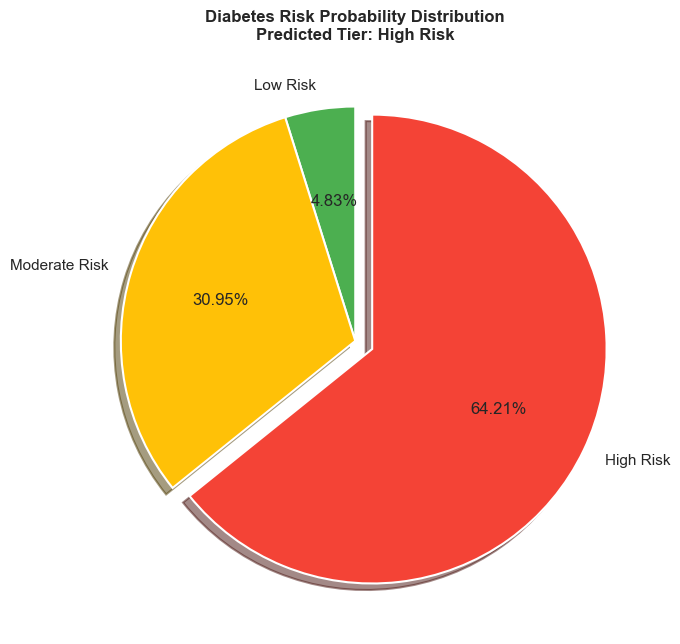

In [12]:
# 1. Save the best model pipeline to disk (assuming this was already run)
model_filename = 'diabetes_risk_model.pkl'
# joblib.dump(best_model, model_filename)
# print(f"✔ Model successfully saved as '{model_filename}'")

# 2. Create an Inference Function with a 3D Pie Chart Visualization
def predict_diabetes_risk(patient_data_dict):
    """
    Takes a dictionary of patient clinical/lifestyle features,
    runs it through the saved preprocessing & tuning pipeline,
    prints the text report, and displays a 3D-styled probability pie chart.
    """
    # Load the model
    loaded_model = joblib.load(model_filename)

    # Convert dictionary to DataFrame (single row)
    input_df = pd.DataFrame([patient_data_dict])

    # Predict risk class (0: Low, 1: Moderate, 2: High)
    pred_class = loaded_model.predict(input_df)[0]
    pred_proba = loaded_model.predict_proba(input_df)[0]

    risk_labels = {0: 'Low Risk', 1: 'Moderate Risk', 2: 'High Risk'}

    # Print Text Report
    print("\n--- PATIENT RISK PREDICTION REPORT ---")
    print(f"Predicted Risk Tier: {risk_labels[pred_class]}")
    print("Class Probabilities:")
    print(f"  - Low Risk:      {pred_proba[0]*100:.2f}%")
    print(f"  - Moderate Risk: {pred_proba[1]*100:.2f}%")
    print(f"  - High Risk:     {pred_proba[2]*100:.2f}%")
    print("--------------------------------------")

    # Generate and Display 3D-Styled Pie Chart
    labels = ['Low Risk', 'Moderate Risk', 'High Risk']
    colors = ['#4CAF50', '#FFC107', '#F44336']  # Green, Yellow/Amber, Red
    
    # Automatically "explode" (pull out) the highest probability slice for emphasis
    max_idx = pred_proba.argmax()
    explode = [0.08 if i == max_idx else 0 for i in range(len(pred_proba))]

    plt.figure(figsize=(7, 7))
    plt.pie(
        pred_proba * 100, 
        labels=labels, 
        autopct='%1.2f%%', 
        startangle=90, 
        colors=colors, 
        shadow=True,              # Adds the 3D shadow effect
        explode=explode,          # Pulls out the main predicted risk slice
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
    )
    plt.title(f"Diabetes Risk Probability Distribution\nPredicted Tier: {risk_labels[pred_class]}", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

# 3. Test the function with a sample patient profile
sample_patient = {
    'age': 52,
    'gender': 'Male',
    'city': 'Mumbai',
    'bmi': 31.5,
    'family_history_diabetes': 'Yes',
    'physical_activity_level': 'Sedentary',
    'diet_type': 'Non-Vegetarian',
    'smoking_status': 'Current',
    'alcohol_consumption': 'Regular',
    'hours_sleep_per_night': 6.0,
    'stress_level': 8,
    'fasting_blood_sugar': 185,
    'hba1c_level': 7.8,
    'blood_pressure_systolic': 150,
    'blood_pressure_diastolic': 95,
    'waist_circumference_cm': 110.0,
    'income_bracket': 'Middle'
}

# Run the prediction and show 3D chart
predict_diabetes_risk(sample_patient)